In [1]:
import os
import itertools
import numpy as np
import pandas as pd
import scanpy as sc
import gseapy as gp
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from anndata import AnnData
from typing import Tuple, Literal
from scipy.stats import pearsonr
from tqdm.auto import tqdm

/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
for mod in [np, pd, sc, gp]:
    print(mod, mod.__version__)

<module 'numpy' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/numpy/__init__.py'> 2.1.0
<module 'pandas' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/pandas/__init__.py'> 2.2.3
<module 'scanpy' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/scanpy/__init__.py'> 1.11.1
<module 'gseapy' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/gseapy/__init__.py'> 1.1.8


In [3]:
def vprint(msg, verbose):
    if verbose:
        print(msg)

def get_genesets(
    adata: AnnData,
    df_hcd_all: pd.DataFrame,
    celltype_signature: str,
    direction: str,
    threshold_pval: float,
    threshold_lfc: float, 
) -> Tuple[dict[str, list[str]], pd.DataFrame]:

    # construct signature gene set
    select = ((df_hcd_all.adj_p_value <= threshold_pval) & (df_hcd_all.celltype == celltype_signature))
    if direction == "upregulated":
        select = select & (df_hcd_all.log_fc >= threshold_lfc)
    elif direction == "downregulated":
        select = select & (df_hcd_all.log_fc <= threshold_lfc)
    elif direction == "both":
        select = select & (df_hcd_all.log_fc.abs() >= threshold_lfc)         
    else:
        raise ValueError()
    df_hcd_ct = df_hcd_all.loc[select]
    
    gene_set_dict = {}
    gene_set_df = pd.DataFrame()
    for cytokine_i, cytokine in enumerate(df_hcd_ct.cytokine.unique()):
        gene_set = df_hcd_ct.loc[df_hcd_ct.cytokine == cytokine].gene.values
        gene_set_shared = np.intersect1d(gene_set, adata.var_names)
        gene_set_df.loc[cytokine_i, "cytokine"] = cytokine
        gene_set_df.loc[cytokine_i, "num_genes_signature"] = len(gene_set)
        gene_set_df.loc[cytokine_i, "num_shared_genes_signature"] = len(gene_set_shared)
        gene_set_df.loc[cytokine_i, "frac_shared_genes_signature"] = len(gene_set_shared) / len(gene_set)
        gene_set_dict[cytokine] = gene_set_shared        

    return gene_set_dict, gene_set_df


def compute_mu_and_sigma(adata: AnnData, contrast_column: str, condition: str) -> pd.DataFrame:

    group = adata[adata.obs[contrast_column] == condition]
    num_cells = group.shape[0]
    X = group.X.toarray() if hasattr(group.X, "toarray") else group.X
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0, ddof=1)
    return {"mu": mu, "sigma": sigma, "num_cells": num_cells}


def compute_s2n(
    adata: AnnData, 
    contrast_column: str, 
    condition_1: str, 
    condition_2: str,
    precomputed_stats: dict | None = None
    
) -> (pd.DataFrame, pd.DataFrame):
    """
    Compute the signal-to-noise ratio (S2N) for each gene between two conditions in an AnnData object.

    Parameters:
    - adata: AnnData object with gene expression data.
    - contrast_column: Key in `adata.obs` indicating the condition labels (e.g. "disease_state").
    - condition_1: Name of the first condition (e.g., "flare").
    - condition_2: Name of the second condition (e.g., "healthy").
    
    Returns:
    - s2n_scores: pandas Series of S2N values indexed by gene names.
    """

    if precomputed_stats is None:
    
        # Select cells for each condition
        group1 = adata[adata.obs[contrast_column] == condition_1]
        group2 = adata[adata.obs[contrast_column] == condition_2]
    
        # print("group1.shape", group1.shape)
        # print("group2.shape", group2.shape)
        
        # number of cells per condition
        num_cells_1 = group1.shape[0]
        num_cells_2 = group2.shape[0]
        
        # Get expression matrices
        X1 = group1.X.toarray() if hasattr(group1.X, "toarray") else group1.X
        X2 = group2.X.toarray() if hasattr(group2.X, "toarray") else group2.X
    
        # Compute mean and std per gene
        mu1 = np.mean(X1, axis=0)
        mu2 = np.mean(X2, axis=0)
        sigma1 = np.std(X1, axis=0, ddof=1)
        sigma2 = np.std(X2, axis=0, ddof=1)

    else:
        vprint("Using precomputed stats", True)
        num_cells_1 = precomputed_stats[condition_1]["num_cells"]
        num_cells_2 = precomputed_stats[condition_2]["num_cells"]
        mu1 = precomputed_stats[condition_1]["mu"]
        mu2 = precomputed_stats[condition_2]["mu"]
        sigma1 = precomputed_stats[condition_1]["sigma"]
        sigma2 = precomputed_stats[condition_2]["sigma"]

    # Compute S2N
    s2n = (mu1 - mu2) / (sigma1 + sigma2 + 1e-8)  # epsilon to avoid division by zero

    num_cells = pd.DataFrame(index=[f"{condition_1}_vs_{condition_2}"], columns=["num_cells_1", "num_cells_2"], data=[[num_cells_1, num_cells_2]])
    stats = pd.DataFrame(s2n, index=adata.var_names, columns=[f"{condition_1}_vs_{condition_2}"])
    
    return stats, num_cells

  
def compute_ranking_statistic(adata: AnnData, contrast_column: str, contrasts: list[Tuple[str, str]]) -> (pd.DataFrame, pd.DataFrame):
    rnk_stats, num_cells = [], []
    precomputed_stats = {}

    conditions = []
    for condition in contrasts:
        conditions.extend([condition[0], condition[1]])
    conditions = np.unique(conditions)
    
    for condition in conditions:
        precomputed_stats[condition] = compute_mu_and_sigma(
            adata, 
            contrast_column=contrast_column, 
            condition=condition
        )

    for condition in contrasts:
        _rnk_stats, _num_cells = compute_s2n(
            adata,
            contrast_column=contrast_column,
            condition_1=condition[0],
            condition_2=condition[1],
            precomputed_stats=precomputed_stats,
        )
        rnk_stats.append(_rnk_stats)
        num_cells.append(_num_cells)
    return pd.concat(rnk_stats, axis=1), pd.concat(num_cells, axis=0)

    
def run_enrichment_test(
    adata: AnnData,
    df_hcd_all: pd.DataFrame,
    celltype: Tuple[str, str] = ("B cell", "B"),
    direction: str = "upregulated",
    threshold_pval: float = 0.01,
    threshold_lfc: float = 1.,
    threshold_expression: float = 0,
    contrast_column: str = "disease_state",
    celltype_column: str = "disease_state",
    contrasts: Tuple[str, str] | list[Tuple[str, str]] = None,
    min_size: int = 10,
    max_size: int = 1000,
    permutation_num: int = 1000,
    weight: float = 1.,
    max_obs_per_condition: int | None = None, # None = all
    seed: int = 2025,
    verbose: bool = True,
    threads: int = 6,
    min_num_cells: int = 20,
) -> pd.DataFrame:

    if not isinstance(contrasts, list):
        assert isinstance(contrasts, Tuple)
        contrasts = [contrasts]
        
    celltype_adata = celltype[0]
    celltype_signature = celltype[1]
    
    # filter for cell type
    vprint("Filter for cell type:", verbose)
    adata = adata[adata.obs[celltype_column] == celltype_adata]
    if adata.shape[0] < min_num_cells:
        print(f"To few cells: {adata.shape[0]}")
        return None

    contrast_value_counts = adata.obs.loc[:, "disease_state"].value_counts()
    print(contrast_value_counts)
    valid_contrast_values = contrast_value_counts.index[contrast_value_counts >= min_num_cells].values
    print(valid_contrast_values)
    adata = adata[(adata.obs.loc[:, contrast_column].isin(valid_contrast_values))]
    remaining_contrasts = []
    for contrast in contrasts:
        if not contrast[0] in valid_contrast_values:
            print(f"Removing contrast: {contrast}")
            continue
        if not contrast[1] in valid_contrast_values:
            print(f"Removing contrast: {contrast}")
            continue
        remaining_contrasts.append(contrast)
    print(f"Updated contrasts are: {remaining_contrasts}")
    contrasts = remaining_contrasts
    if len(contrasts) == 0:
        return None
        
    vprint("Filter for cell type: done.", verbose)
    
    # filter based on gene expression
    vprint("Filter for gene expression:", verbose)
    adata = adata[:, adata.X.mean(axis=0) >= threshold_expression]
    vprint("Filter for gene expression: done.", verbose)

    # get genesets
    vprint("Get gene sets:", verbose)
    gene_set_dict, gene_set_df = get_genesets(
        adata=adata,
        df_hcd_all=df_hcd_all,
        celltype_signature=celltype_signature,
        direction=direction,
        threshold_pval=threshold_pval,
        threshold_lfc=threshold_lfc,
    )
    vprint("Get gene sets: done.", verbose)
    
    # compute ranking stat
    vprint("Get ranking stats:", verbose)
    rnk_stats, num_cells_per_condition = compute_ranking_statistic(adata, contrast_column=contrast_column, contrasts=contrasts)
    vprint("Get ranking stats: done.", verbose)
    results = []
    
    for contrast_name in rnk_stats.columns:
        print(contrast_name)
        # format stat so that it can be processed be gseapy
        rnk = rnk_stats.loc[:, contrast_name]\
            .replace([np.inf, -np.inf], np.nan)\
            .dropna()\
            .sort_values(ascending=False)\
            .to_frame()\
            .rename({contrast_name: 1}, axis=1)\
            .rename_axis("0")
        
        # run enrichment
        gp_res = gp.prerank(
            rnk=rnk,
            gene_sets=gene_set_dict,
            min_size=min_size,
            max_size=max_size,
            permutation_num=permutation_num,
            weight=weight,
            outdir=None,
            seed=seed,
            verbose=verbose,
            threads=threads,
        )
        _res = gp_res.res2d
        _res.loc[:, "contrast"] = contrast_name
        _res.loc[:, "num_cells_1"] = num_cells_per_condition.loc[contrast_name, "num_cells_1"]
        _res.loc[:, "num_cells_2"] = num_cells_per_condition.loc[contrast_name, "num_cells_2"]
        _res.loc[:, "percent_duplicate_ranking_stats"] = (rnk.duplicated(keep="first").sum() / rnk.shape[0]) * 100
        results.append(_res)
        vprint(f"{contrast_name}: done.", verbose)

    # combine results and save hyperparams
    results = pd.concat(results, axis=0, ignore_index=True)
    results.loc[:, "celltype_adata"] = celltype_adata
    results.loc[:, "celltype_signature"] = celltype_signature
    results.loc[:, "celltype_combo"] = f"{celltype_adata} ({celltype_signature})"
    results.loc[:, "direction"] = direction
    results.loc[:, "threshold_pval"] = threshold_pval
    results.loc[:, "threshold_lfc"] = threshold_lfc
    results.loc[:, "threshold_expression"] = threshold_expression
    results.loc[:, "min_size"] = min_size
    results.loc[:, "max_size"] = max_size
    results.loc[:, "permutation_num"] = permutation_num
    results.loc[:, "weight"] = weight
    results.loc[:, "seed"] = seed
    results.loc[:, "threads"] = threads

    results.rename({"Term": "cytokine"}, inplace=True, axis=1)
    results = pd.merge(results, gene_set_df, on="cytokine")
    
    return results

In [7]:
df_hcd_all = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/data/DEGs/DEGs_all_with_pbs_DE_count.csv", index_col=0)
questionable_genes = set(pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/01_overview/questionable_genes.csv")['gene'])
df_hcd_all = df_hcd_all.loc[
    (
        (df_hcd_all['pbs_well'] > 3) 
        & (~df_hcd_all['gene'].isin(questionable_genes))
        & (df_hcd_all['adj_p_value'] < 0.05)
    )
]

In [8]:
hcd_celltypes = df_hcd_all.celltype.unique()
hcd_celltypes

array(['Intermediate_B_cell', 'NKT', 'CD8_Memory_T_cell', 'NK_CD56low',
       'CD16_Mono', 'NK_CD56hi', 'CD8_Naive_T_cell', 'pDC', 'ILC', 'MAIT',
       'Naive_B_cell', 'CD4_Naive_T_cell', 'Treg', 'Plasmablast',
       'Granulocyte', 'B_cell', 'CD4_T_cell', 'HSPC', 'CD8_T_cell',
       'CD14_Mono', 'cDC', 'CD4_Memory_T_cell', 'NK', 'Mono'],
      dtype=object)

In [9]:
adata = sc.read_h5ad("/Users/soeren.becker/repos/HumanCytokineDict/data/use_case_datasets/06_lupus/lupus_norm_log1p.h5ad")

In [11]:
adata.obs.head(2)

,library_uuid,cell_type_ontology_term_id,author_cell_type,cell_state,sample_uuid,development_stage_ontology_term_id,disease_state,suspension_uuid,donor_id,self_reported_ethnicity_ontology_term_id,disease_ontology_term_id,sex_ontology_term_id,Processing_Cohort,ct_cov,ind_cov,cell_type,disease,sex,self_reported_ethnicity,development_stage
cellId,,,,,,,,,,,,,,,,,,,,
CAAGGCCAGTATCGAA-1-1-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-1-0-0-0-0-0,3332f018-936e-4c4c-9105-99d9503db5a3,CL:0000624,T4,na,0a1148dc-356f-4dc4-9c32-bf0823257d93,HsapDv:0000122,na,cc418a0a-d636-4eca-a44c-db537d30b486,HC-546,HANCESTRO:0008,PATO:0000461,PATO:0000383,4.0,T4_naive,HC-546,"CD4-positive, alpha-beta T cell",normal,female,Asian,28-year-old human stage
CTAACTTCAATGAATG-1-1-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-1-0-0-0-0-0,70a004b7-4a17-4702-8910-4557aa0c4279,CL:0000860,cM,na,577bce84-8d37-4851-9fb4-53f9467699ba,HsapDv:0000139,managed,3e67947f-bd15-4d41-910a-89488e72c50a,1132,HANCESTRO:0005,MONDO:0007915,PATO:0000383,4.0,NaN,1132_1132,classical monocyte,systemic lupus erythematosus,female,European,45-year-old human stage


In [13]:
adata.obs.self_reported_ethnicity.value_counts(dropna=False)

self_reported_ethnicity
European                      738773
Asian                         503999
African American               13218
Hispanic or Latin American      7686
Name: count, dtype: int64

In [14]:
adata = adata[adata.obs.self_reported_ethnicity == "Asian"]

In [15]:
# df_mart_conversion = pd.read_csv("/Users/soeren.becker/Downloads/mart_export (1).txt", skiprows=0, sep="\t")
# df_mart_conversion.columns = [c.strip().lower().replace(" ", "_") for c in df_mart_conversion.columns]
# id_to_symbol = dict(zip(df_mart_conversion['gene_stable_id'], df_mart_conversion['hgnc_symbol']))
# adata.var['ensembl_id'] = adata.var_names
# adata.var['gene_symbol'] = adata.var_names.map(id_to_symbol)

In [16]:
ensembl_to_symbol = pd.read_pickle("/Users/soeren.becker/repos/HumanCytokineDict/data/use_case_datasets/06_lupus/ens_id_to_symbol.pkl")
adata.var['gene_symbol'] = adata.var_names.map(ensembl_to_symbol)
adata.var.loc[:, "new_index"] = adata.var.gene_symbol
adata.var.loc[adata.var.new_index.isna(), "new_index"] = adata.var.loc[adata.var.new_index.isna()].index
adata.var = adata.var.reset_index().set_index("new_index")
display(adata.var)

display(adata.var_names.value_counts())

adata.var_names_make_unique()

/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_16852/3326041267.py:2: ImplicitModificationWarning: Trying to modify attribute `.var` of view, initializing view as actual.
  adata.var['gene_symbol'] = adata.var_names.map(ensembl_to_symbol)


,ensemble_id,mean_expr_raw,frac_expr_cells,mean_expr_log1p,gene_symbol
new_index,,,,,
MIR1302-2HG,ENSG00000243485,0.000002,2,9.684404e-07,MIR1302-2HG
FAM138A,ENSG00000237613,0.000000,0,0.000000e+00,FAM138A
OR4F5,ENSG00000186092,0.000000,0,0.000000e+00,OR4F5
ENSG00000238009,ENSG00000238009,0.000629,789,3.820327e-04,None
ENSG00000239945,ENSG00000239945,0.000043,54,2.426126e-05,None
...,...,...,...,...,...
ND4L,ENSG00000212907,0.926157,631545,4.517487e-01,ND4L
ND4,ENSG00000198886,8.619816,1237245,2.010944e+00,ND4
ND5,ENSG00000198786,2.380893,990371,9.433077e-01,ND5


new_index
Metazoa_SRP        4
PINX1              2
MGAT4EP            2
SIGLEC5            2
FAM66E             2
                  ..
ENSG00000261068    1
TAF8               1
ENSG00000223946    1
CCND3              1
CYTB               1
Name: count, Length: 30917, dtype: int64

In [17]:
celltype_combos = (
    ("B cell", "B_cell"),
    ('CD4-positive, alpha-beta T cell', "CD4_T_cell"),
    ('CD8-positive, alpha-beta T cell', "CD8_T_cell"),
    ('classical monocyte', "CD14_Mono"),
    ('non-classical monocyte', "CD16_Mono"),
    ('natural killer cell', "NK_CD56hi"),
    ('natural killer cell', "NK_CD56low"),
    ('conventional dendritic cell', "cDC"),
)

for combo in celltype_combos:
    assert combo[1] in hcd_celltypes

In [18]:
contrasts = [('flare', 'na')]

In [19]:
adata.obs.cell_type.value_counts()

cell_type
classical monocyte                 134856
CD4-positive, alpha-beta T cell    129242
CD8-positive, alpha-beta T cell    108395
B cell                              66639
natural killer cell                 31673
non-classical monocyte              19962
conventional dendritic cell          6739
lymphocyte                           4020
plasmacytoid dendritic cell          1421
plasmablast                           747
progenitor cell                       305
Name: count, dtype: int64

In [20]:
if False:
    # saving per cell type to avoid OOM errors

    for celltype in adata.obs.cell_type.unique():
        print(f"Saving {celltype}")
        adata[adata.obs.cell_type == celltype].write_h5ad(
            f"/Users/soeren.becker/repos/HumanCytokineDict/data/use_case_datasets/06_lupus/lupus_norm_log1p_{celltype}.h5ad"
        )
    del adata

In [5]:
result_dir = "./results_robustness_final_DEGs_Asian"
os.makedirs(result_dir, exist_ok=True)

In [25]:
threshold_pval = 0.05

all_results = []

for celltype_combo_k, celltype_combo in enumerate(celltype_combos):
    # all_results = []
    print(celltype_combo)
    shared_kwargs = {
        "threshold_pval": threshold_pval,
        "direction": "upregulated",
        "min_size": 8,
        "max_size": 1_000,
        "permutation_num": 20_000,
        "verbose": True,
        "df_hcd_all": df_hcd_all,
        "adata": adata,
        "min_num_cells": 50,
    }

    for threshold_lfc in [0.8, 0.9, 1, 1.1, 1.2,]:
        shared_kwargs["threshold_lfc"] = threshold_lfc
        
        for threshold_expression in [0.05, 0.06, 0.07, 0.08, 0.09, 0.1]:
            shared_kwargs["threshold_expression"] = threshold_expression

            print(celltype_combo, threshold_lfc, threshold_expression)
            
            results = run_enrichment_test(
                celltype=celltype_combo,
                contrast_column="disease_state",
                celltype_column="cell_type",
                contrasts=contrasts,
                **shared_kwargs,
            )
            
            all_results.append(results)

all_results = pd.concat(all_results, axis=0)
all_results.to_csv(os.path.join(result_dir, "results_lupus_robustness_Asian.csv"))

('B cell', 'B_cell')
Filter for cell type:
disease_state
managed    51650
na         10637
flare       3482
treated      870
Name: count, dtype: int64
['managed', 'na', 'flare', 'treated']
Categories (4, object): ['flare', 'managed', 'na', 'treated']
Updated contrasts are: [('flare', 'na')]
Filter for cell type: done.
Filter for gene expression:
Filter for gene expression: done.
Get gene sets:
Get gene sets: done.
Get ranking stats:


2025-10-27 16:44:02,688 [WARNING] Duplicated values found in preranked stats: 0.05% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2025-10-27 16:44:02,688 [INFO] Parsing data files for GSEA.............................
2025-10-27 16:44:02,690 [INFO] 0060 gene_sets have been filtered out when max_size=1000 and min_size=8
2025-10-27 16:44:02,690 [INFO] 0011 gene_sets used for further statistical testing.....
2025-10-27 16:44:02,690 [INFO] Start to run GSEA...Might take a while..................


Using precomputed stats
Get ranking stats: done.
flare_vs_na


2025-10-27 16:44:05,976 [INFO] Congratulations. GSEApy runs successfully................



flare_vs_na: done.
Filter for cell type:
disease_state
managed    51650
na         10637
flare       3482
treated      870
Name: count, dtype: int64
['managed', 'na', 'flare', 'treated']
Categories (4, object): ['flare', 'managed', 'na', 'treated']
Updated contrasts are: [('flare', 'na')]
Filter for cell type: done.
Filter for gene expression:
Filter for gene expression: done.
Get gene sets:
Get gene sets: done.
Get ranking stats:


...

flare_vs_na: done.
Filter for cell type:
disease_state
managed    5291
na         1225
flare       121
treated     102
Name: count, dtype: int64
['managed', 'na', 'flare', 'treated']
Categories (4, object): ['flare', 'managed', 'na', 'treated']
Updated contrasts are: [('flare', 'na')]
Filter for cell type: done.
Filter for gene expression:
Filter for gene expression: done.
Get gene sets:
Get gene sets: done.
Get ranking stats:


2025-10-27 17:31:13,026 [INFO] Parsing data files for GSEA.............................
2025-10-27 17:31:13,029 [INFO] 0071 gene_sets have been filtered out when max_size=1000 and min_size=8
2025-10-27 17:31:13,029 [INFO] 0009 gene_sets used for further statistical testing.....
2025-10-27 17:31:13,030 [INFO] Start to run GSEA...Might take a while..................


Using precomputed stats
Get ranking stats: done.
flare_vs_na


2025-10-27 17:31:14,138 [INFO] Congratulations. GSEApy runs successfully................



flare_vs_na: done.


In [9]:
def _check_robustness_fractions(
    df_pivot, 
    threshold_qval=0.1, # adjusted p value
    threshold_valid=0.5, # fraction of results required to even consider this condition. I.e. if the test only ran for one set of thresholds, then it is not very robust.
    threshold_below_alpha=0.75, # fraction of results that need to be significant
):
    n_total = np.prod(df_pivot.shape)
    n_valid = n_total - df_pivot.isna().sum().sum()
    n_below_alpha = (df_pivot < threshold_qval).sum().sum() # number of results below pval threshold, i.e., number of significant results
    frac_valid_results = (n_valid / n_total)
    frac_pval_below_alpha = (n_below_alpha / n_valid) # fraction of significant results relative to valid results
    is_robust = (frac_pval_below_alpha > threshold_below_alpha) & (frac_valid_results > threshold_valid)
    return frac_valid_results, frac_pval_below_alpha, is_robust


def check_robustness(
    all_results,
    THRESHOLD_QVAL = 0.1,
    THRESHOLD_VALID = 0.5,
    THRESHOLD_BELOW_ALPHA = 0.9,
):
    
    all_thresholds_expression = all_results.threshold_expression.sort_values(ascending = False).unique()
    all_thresholds_lfc = sorted(all_results.threshold_lfc.unique())
    
    df = pd.DataFrame(index=all_thresholds_expression, columns=all_thresholds_lfc)
    df.index.rename("threshold_expression", inplace=True)
    df.columns.rename("threshold_lfc", inplace=True)

    df2 = df.copy()
    
    robust_results = []
    
    for contrast in tqdm(all_results.contrast.unique()):
        for celltype_combo in all_results.celltype_combo.unique():
            results_ct = all_results.loc[(all_results.celltype_combo == celltype_combo) & (all_results.contrast == contrast)]
            for cytokine in results_ct.cytokine.unique():
                results_ct_cy = results_ct.loc[results_ct.cytokine == cytokine]
                df_pivot = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="FDR q-val")
                df_pivot_nes = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="NES")
                row_order = df_pivot.index.sort_values(ascending=False)
                with warnings.catch_warnings():
                    warnings.simplefilter(action='ignore', category=FutureWarning)
                    df_combined = pd.concat([df, df_pivot])
                    df_combined2 = pd.concat([df2, df_pivot_nes])
                df_merged = df_combined.combine_first(df_pivot)
                df_merged2 = df_combined2.combine_first(df_pivot_nes)
                df_merged = df_merged.loc[~df_merged.index.duplicated()]
                df_merged2 = df_merged2.loc[~df_merged2.index.duplicated()]
                df_pivot = df_merged.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                df_pivot_nes = df_merged2.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                frac_valid_results, frac_pval_below_alpha, is_robust = _check_robustness_fractions(
                    df_pivot,
                    threshold_qval=THRESHOLD_QVAL,
                    threshold_valid=THRESHOLD_VALID,
                    threshold_below_alpha=THRESHOLD_BELOW_ALPHA
                )
                
                if is_robust:
                    # print(df_pivot_nes.max().max(), df_pivot_nes.min().min())
                    if (df_pivot_nes.max().max() > 0) and (df_pivot_nes.min().min() < 0):
                        sns.heatmap(df_pivot, cmap="Reds_r", center=0, vmin=0, vmax=0.1, square=True)
                        plt.show()
                        sns.heatmap(df_pivot_nes, cmap="RdBu_r", center=0, square=True)
                        plt.show()
                    robust_results.append(
                        (
                            celltype_combo, contrast, cytokine,
                            frac_valid_results, frac_pval_below_alpha, is_robust,
                            results_ct_cy.NES.min(), results_ct_cy.NES.max(),
                            THRESHOLD_QVAL,
                            THRESHOLD_BELOW_ALPHA,
                        )
                    )
        
    robust_results = pd.DataFrame(robust_results).rename(
        {0: "celltype_combo", 1: "contrast", 2: "cytokine", 3: "frac_valid", 4: "frac_significant", 5:"is_robust", 6:"NES_min", 7:"NES_max", 8:"qval_threshold", 9: "threshold_frac_below_alpha"},
        axis=1
    )
    return robust_results

    

def check_robustness_old(
    all_results,
    THRESHOLD_QVAL = 0.1,
    THRESHOLD_VALID = 0.5,
    THRESHOLD_BELOW_ALPHA = 0.9,
):
    
    all_thresholds_expression = all_results.threshold_expression.sort_values(ascending = False).unique()
    all_thresholds_lfc = sorted(all_results.threshold_lfc.unique())
    
    df = pd.DataFrame(index=all_thresholds_expression, columns=all_thresholds_lfc)
    df.index.rename("threshold_expression", inplace=True)
    df.columns.rename("threshold_lfc", inplace=True)
    
    robust_results = []
    
    for contrast in tqdm(all_results.contrast.unique()):
        for celltype_combo in all_results.celltype_combo.unique():
            results_ct = all_results.loc[(all_results.celltype_combo == celltype_combo) & (all_results.contrast == contrast)]
            for cytokine in results_ct.cytokine.unique():
                results_ct_cy = results_ct.loc[results_ct.cytokine == cytokine]
                df_pivot = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="FDR q-val")
                row_order = df_pivot.index.sort_values(ascending=False)
                with warnings.catch_warnings():
                    warnings.simplefilter(action='ignore', category=FutureWarning)
                    df_combined = pd.concat([df, df_pivot])
                df_merged = df_combined.combine_first(df_pivot)
                df_merged = df_merged.loc[~df_merged.index.duplicated()]
                df_pivot = df_merged.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                frac_valid_results, frac_pval_below_alpha, is_robust = _check_robustness_fractions(
                    df_pivot,
                    threshold_qval=THRESHOLD_QVAL,
                    threshold_valid=THRESHOLD_VALID,
                    threshold_below_alpha=THRESHOLD_BELOW_ALPHA
                )
                
                if is_robust:
                    robust_results.append(
                        (
                            celltype_combo, contrast, cytokine,
                            frac_valid_results, frac_pval_below_alpha, is_robust,
                            results_ct_cy.NES.min(), results_ct_cy.NES.max(),
                            THRESHOLD_QVAL,
                            THRESHOLD_BELOW_ALPHA,
                        )
                    )
        
    robust_results = pd.DataFrame(robust_results).rename(
        {0: "celltype_combo", 1: "contrast", 2: "cytokine", 3: "frac_valid", 4: "frac_significant", 5:"is_robust", 6:"NES_min", 7:"NES_max", 8:"qval_threshold", 9: "threshold_frac_below_alpha"},
        axis=1
    )
    return robust_results


def get_robust_significant_results(
    results,
    alphas = [0.1, 0.05, 0.01],
):

    results_robust = []
    for alpha in alphas:
        results_robust.append(check_robustness(results, THRESHOLD_QVAL=alpha, THRESHOLD_VALID=THRESHOLD_VALID, THRESHOLD_BELOW_ALPHA=THRESHOLD_BELOW_ALPHA))
    results_robust = pd.concat(results_robust)
    results_robust = results_robust.groupby(["contrast", "celltype_combo", "cytokine"])["qval_threshold"].min().to_frame().reset_index()
    
    results_mean = results.fillna(0).groupby(["contrast", "celltype_combo", "cytokine"])["NES"].mean().to_frame().reset_index()
    results_pivot = results_mean.pivot(
        index="cytokine",
        columns="celltype_combo",
        values="NES",
    )
    df_annot = results_pivot.copy()
    with warnings.catch_warnings():
        warnings.simplefilter(action='ignore', category=FutureWarning)
        df_annot[:] = ""
    for cytokine in df_annot.index:
        for celltype in df_annot.columns:
            qval = results_robust.loc[(results_robust.cytokine == cytokine) & (results_robust.celltype_combo == celltype)].qval_threshold
            if len(qval) != 0:
                qval = qval.values[0]
                if qval == 0.1:
                    df_annot.loc[cytokine, celltype] = "*"
                if qval == 0.05:
                    df_annot.loc[cytokine, celltype] = "**"
                if qval == 0.01:
                    df_annot.loc[cytokine, celltype] = "***"

    return results_pivot, df_annot, results_robust


def format_cytokine_names(x):
    if isinstance(x, (list, np.ndarray, pd.Index)):
        return [format_cytokine_names(_x) for _x in x]
    text = x.get_text() if hasattr(x, 'get_text') else x
    text = text.replace("beta", r"$\beta$")
    text = text.replace("alpha", r"$\alpha$")
    text = text.replace("gamma", r"$\gamma$")
    text = text.replace("lambda", r"$\lambda$")
    text = text.replace("omega", r"$\omega$")
    return text


def format_celltype_names(x):
    if isinstance(x, (list, np.ndarray, pd.Index)):
        return [format_celltype_names(_x) for _x in x]
    text = x.get_text() if hasattr(x, 'get_text') else x
    # text = text.replace("CD4-positive, alpha-beta T cell", r"CD4, $\alpha$-$\beta$ T")
    text = text.replace("CD4-positive, alpha-beta T cell", r"CD4 T")
    # text = text.replace("CD8-positive, alpha-beta T cell", r"CD8, $\alpha$-$\beta$ T")
    text = text.replace("CD8-positive, alpha-beta T cell", r"CD8 T")
    text = text.replace("conventional dendritic cell", "cDC")
    text = text.replace("natural killer cell", "NK")
    if not text.startswith("NK"):
        text = text.split("(")[0]
    else:
        #text = text.replace("CD56-bright_NK", "CD56hi")
        #text = text.replace("CD56-dim_NK", "CD56low")
        #text = text.replace("NK_CD56hi", "CD56hi")
        text = text.replace("NK_CD56hi", "hi")
        #text = text.replace("NK_CD56low", "CD56low")
        text = text.replace("NK_CD56low", "low")
    if text.startswith("non-classical monocyte"):
        text =  "nc. Mono."
    elif text.startswith("classical monocyte"):
        text =  "c. Mono."
    return text

In [6]:
all_results = pd.read_csv(os.path.join(result_dir, "results_lupus_robustness_Asian.csv"))

In [7]:
all_results.percent_duplicate_ranking_stats.max()

np.float64(0.0938967136150234)

In [8]:
THRESHOLD_VALID = 1/3
THRESHOLD_BELOW_ALPHA = 2/3

In [11]:
results_pivot, df_annot, results_robust = get_robust_significant_results(all_results)

100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.86it/s]


In [13]:
results_pivot

celltype_combo,B cell (B_cell),"CD4-positive, alpha-beta T cell (CD4_T_cell)","CD8-positive, alpha-beta T cell (CD8_T_cell)",classical monocyte (CD14_Mono),conventional dendritic cell (cDC),natural killer cell (NK_CD56hi),natural killer cell (NK_CD56low),non-classical monocyte (CD16_Mono)
cytokine,,,,,,,,
C5a,NaN,NaN,NaN,-1.195722,NaN,NaN,NaN,1.340396
CD40L,1.518290,NaN,NaN,NaN,NaN,NaN,NaN,NaN
GM-CSF,NaN,NaN,NaN,-1.275188,-0.832487,NaN,NaN,1.313946
IFN-alpha1,NaN,2.267503,2.316494,2.362408,2.248164,NaN,2.212494,2.025210
IFN-beta,2.401972,2.459520,2.453139,2.346879,2.500862,2.624913,2.546409,2.477820
IFN-gamma,2.174641,2.154860,2.311434,2.066189,2.125886,2.220637,2.312953,1.839050
IFN-omega,2.244327,2.396591,2.457173,2.281834,2.476732,2.564929,2.538189,2.474673
IL-1-alpha,NaN,2.112525,2.173438,0.965162,1.438087,NaN,NaN,NaN
IL-1-beta,1.852405,2.127450,2.263585,1.724789,1.535584,1.090330,2.316857,1.787135


In [17]:
CELLTYPE_ORDER = [
    'B cell (B_cell)',
    'CD4-positive, alpha-beta T cell (CD4_T_cell)',
    'CD8-positive, alpha-beta T cell (CD8_T_cell)', 
    'natural killer cell (NK_CD56hi)',
    'natural killer cell (NK_CD56low)',
    'classical monocyte (CD14_Mono)',   
    'non-classical monocyte (CD16_Mono)',
    'conventional dendritic cell (cDC)',
]

FONTSIZE = 6

In [24]:
fig_path = "./results_robustness_final_DEGs_Asian"

## all cytokines

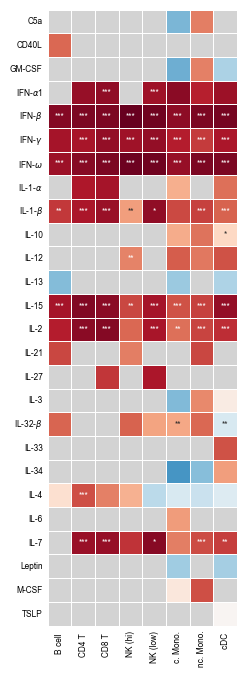

In [19]:
results_pivot = results_pivot.T.loc[CELLTYPE_ORDER].T

fig, ax = plt.subplots(1,1,figsize=(8, 8))
sns.heatmap(
    results_pivot,
    square=True,
    annot=df_annot,
    cmap="RdBu_r",
    center=0,
    # vmin=vmin,
    # vmax=vmax,
    annot_kws={"fontsize": 6, "family": "Arial"},
    linecolor="white",
    fmt="",
    linewidths=0.5,
    cbar=False,
    ax=ax,
)

plt.xlabel("")
plt.ylabel("")
ax.set_facecolor("lightgray")
ax.tick_params(axis='both', which='both', length=0)

celltype_labels = format_celltype_names(results_pivot.columns)
plt.xticks(0.5+np.arange(results_pivot.shape[1]), celltype_labels, fontsize=FONTSIZE, family="Arial", rotation=90, ha="center")

cytokine_labels = format_cytokine_names(results_pivot.index)
plt.yticks(0.5+np.arange(results_pivot.shape[0]), cytokine_labels, fontsize=FONTSIZE, family="Arial", rotation=0, ha="right")

plt.show()

In [20]:
selected_cytokines = [
    "IFN-beta",
    "IFN-gamma",
    "IL-15",
    "IL-4", 
    # "IL-1-beta",
    "IL-32-beta",
    # "Leptin",
    "M-CSF",
]

## Selected cytokines

### horizontal

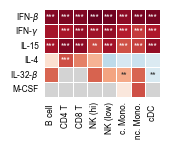

In [25]:
results_pivot_selected = results_pivot.loc[selected_cytokines]
df_annot_selected = df_annot.loc[selected_cytokines]

fig, ax = plt.subplots(1,1,figsize=(1.5, 1.5))
sns.heatmap(
    results_pivot_selected,
    square=True,
    annot=df_annot_selected,
    cmap="RdBu_r",
    center=0,
    # vmin=vmin,
    # vmax=vmax,
    annot_kws={"fontsize": 6, "family": "Arial"},
    linecolor="white",
    fmt="",
    linewidths=0.5,
    cbar=False,
    ax=ax,
)

plt.xlabel("")
plt.ylabel("")
ax.set_facecolor("lightgray")
ax.tick_params(axis='both', which='both', length=0)

celltype_labels = format_celltype_names(results_pivot_selected.columns)
plt.xticks(0.5+np.arange(results_pivot_selected.shape[1]), celltype_labels, fontsize=FONTSIZE, family="Arial", rotation=90, ha="center")

cytokine_labels = format_cytokine_names(results_pivot_selected.index)
plt.yticks(0.5+np.arange(results_pivot_selected.shape[0]), cytokine_labels, fontsize=FONTSIZE, family="Arial", rotation=0, ha="right")
plt.show()

### vertical

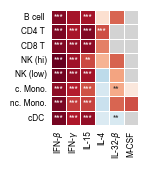

In [26]:
results_pivot_selected = results_pivot_selected.T
df_annot_selected = df_annot_selected.T

fig, ax = plt.subplots(1,1,figsize=(1.5, 1.5))
sns.heatmap(
    results_pivot_selected,
    square=True,
    annot=df_annot_selected,
    cmap="RdBu_r",
    center=0,
    # vmin=vmin,
    # vmax=vmax,
    annot_kws={"fontsize": 6, "family": "Arial"},
    linecolor="white",
    fmt="",
    linewidths=0.5,
    cbar=False,
    ax=ax,
)

plt.xlabel("")
plt.ylabel("")
ax.set_facecolor("lightgray")
ax.tick_params(axis='both', which='both', length=0)

celltype_labels = format_celltype_names(results_pivot_selected.index)
plt.yticks(0.5+np.arange(len(celltype_labels)), celltype_labels, fontsize=FONTSIZE, family="Arial", rotation=0, ha="right")

cytokine_labels = format_cytokine_names(results_pivot_selected.columns)
plt.xticks(0.5+np.arange(len(cytokine_labels)), cytokine_labels, fontsize=FONTSIZE, family="Arial", rotation=90, ha="center")

if True:
    plt.savefig(
        os.path.join(fig_path, "enichment_heatmap_lupus_cytokines_selected_flare_vs_healthy_Asian_T.svg"), 
        bbox_inches="tight", 
        pad_inches=0, 
        dpi=500,
        #transparent=True,
    )

plt.show()